# Practical 05 — Text-to-Image Generation with Stable Diffusion

**Course/Lab:** Generative AI / Deep Learning  
**Student name:** Krishna Kushwah  
**Roll number:** 202401110039

## Aim
Implement a pretrained Stable Diffusion model with Hugging Face Diffusers to generate images from text prompts, and analyse how **inference steps**, **guidance scale**, and **sampling schedulers** affect the generated images.

## Objectives
1. Set up and run a pretrained text-to-image diffusion pipeline.
2. identify the roles of the tokenizer, text encoder, U-Net, scheduler, and VAE.
3. Compare prompt styles and demonstrate the use of a negative prompt.
4. Change one experimental parameter at a time and record visual quality and generation time.

>

## 1. Background and model components

Stable Diffusion is a **latent text-to-image diffusion model**. It starts with a noisy latent representation and repeatedly denoises it while using text embeddings to guide the result. The VAE decoder converts the final latent representation into a normal image.

| Component | Role in the pipeline |
|---|---|
| **Tokenizer** | Splits the text prompt into tokens that the model can process. |
| **Text encoder** | Converts tokens into text embeddings that represent the prompt's meaning. |
| **U-Net** | Predicts the noise present in the latent representation at each denoising step. |
| **Scheduler** | Defines the numerical update used to move from noisy latents toward cleaner latents. |
| **VAE (variational autoencoder)** | Works in compressed image space; its decoder converts the final latent into pixels. |

### Experimental controls
For a fair comparison, keep the prompt, seed, and all other settings constant while changing only the parameter under investigation. Generation time and the visual result are recorded. Quality ratings should be based on the images produced by your own run—not assumed in advance.

## 2. Install dependencies

Run this cell once in the notebook environment. If Colab asks for a runtime restart after installation, restart and run the notebook again from the first cell.

In [ ]:
%pip install -q -U diffusers transformers accelerate safetensors matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


## 3. Import libraries and configure the run

The code uses half precision on a CUDA GPU to reduce memory use, and float32 on CPU for compatibility. A fixed seed helps make comparisons more controlled.

In [ ]:
import time
import re
from pathlib import Path

import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

from diffusers import (
    StableDiffusionPipeline,
    PNDMScheduler,
    DDIMScheduler,
    EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
)

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
SEED = 42
DEFAULT_STEPS = 30
DEFAULT_GUIDANCE = 7.5

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WEIGHT_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
OUTPUT_DIR = Path("stable_diffusion_lab_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {DEVICE}")
print(f"Model: {MODEL_ID}")
print(f"Weight dtype: {WEIGHT_DTYPE}")
if DEVICE == "cpu":
    print("Note: CPU inference can be very slow. A Colab GPU is strongly recommended.")

experiment_results = []

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda
Model: stable-diffusion-v1-5/stable-diffusion-v1-5
Weight dtype: torch.float16


## 4. Load the pretrained Stable Diffusion pipeline

`from_pretrained()` downloads the model files (or loads them from the local cache). The pipeline connects the tokenizer, text encoder, U-Net, scheduler and VAE. This practical performs **inference only**; it does not train or fine-tune the model.

In [ ]:
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=WEIGHT_DTYPE,
    use_safetensors=True,
)
pipe = pipe.to(DEVICE)
pipe.set_progress_bar_config(disable=False)

# Preserve the original scheduler configuration so each scheduler test starts
# from the same base configuration instead of inheriting previous changes.
BASE_SCHEDULER_CONFIG = pipe.scheduler.config

print("Pipeline loaded successfully.")
print("Tokenizer:", type(pipe.tokenizer).__name__)
print("Text encoder:", type(pipe.text_encoder).__name__)
print("U-Net:", type(pipe.unet).__name__)
print("Scheduler:", type(pipe.scheduler).__name__)
print("VAE:", type(pipe.vae).__name__)
print("Safety checker enabled:", pipe.safety_checker is not None)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Pipeline loaded successfully.
Tokenizer: CLIPTokenizer
Text encoder: CLIPTextModel
U-Net: UNet2DConditionModel
Scheduler: PNDMScheduler
VAE: AutoencoderKL
Safety checker enabled: True


## 5. Define reusable helper functions

`generate_image()` generates one image and measures elapsed inference time. `negative_prompt` specifies visual elements to discourage. `show_image_grid()` displays a comparison grid and can save that grid to the output folder.

In [ ]:
NEGATIVE_PROMPT = (
    "blurry, low quality, out of focus, distorted objects, "
    "extra limbs, text, watermark, logo, oversaturated"
)

def generate_image(
    prompt,
    negative_prompt=NEGATIVE_PROMPT,
    steps=DEFAULT_STEPS,
    guidance=DEFAULT_GUIDANCE,
    seed=SEED,
):
    """Generate one image and return (PIL image, elapsed seconds)."""
    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    # Synchronize CUDA before/after timing so asynchronous GPU work is included.
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt if negative_prompt else None,
        num_inference_steps=int(steps),
        guidance_scale=float(guidance),
        generator=generator,
    )
    image = result.images[0]

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return image, elapsed


def slugify(text):
    """Create a simple, file-safe name."""
    return re.sub(r"[^a-zA-Z0-9_-]+", "_", text).strip("_").lower()


def save_image(image, filename):
    path = OUTPUT_DIR / filename
    image.save(path)
    return path


def show_image_grid(images, titles, columns=3, save_name=None):
    if not images:
        print("No images to display.")
        return
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4.8 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]
    for i, ax in enumerate(axes):
        if i < len(images):
            ax.imshow(images[i])
            ax.set_title(titles[i], fontsize=10)
        ax.axis("off")
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=160, bbox_inches="tight")
    plt.show()


def record_result(experiment, variant, prompt, steps, guidance, seed, elapsed, scheduler=None):
    experiment_results.append({
        "experiment": experiment,
        "variant": variant,
        "prompt": prompt,
        "steps": int(steps),
        "guidance_scale": float(guidance),
        "scheduler": scheduler or type(pipe.scheduler).__name__,
        "seed": int(seed),
        "generation_seconds": round(float(elapsed), 3),
    })

## 6. Baseline text-to-image generation

This first prompt is deliberately different from the instructor's example. It describes the subject, setting, lighting and style, which gives the model useful visual details to work with.

  0%|          | 0/30 [00:00<?, ?it/s]

Generation time: 7.03 seconds


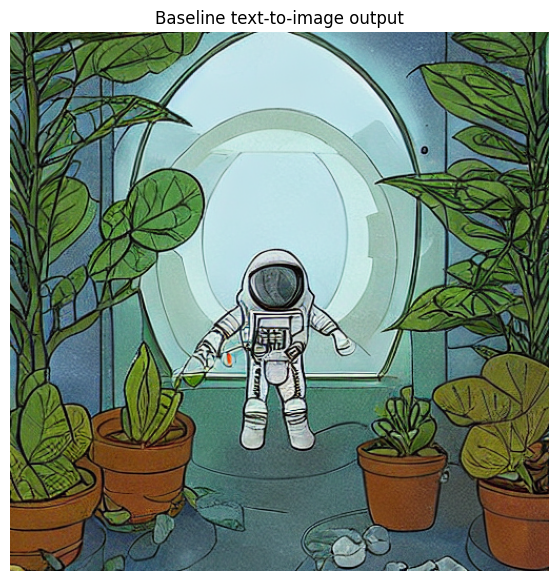

In [ ]:
baseline_prompt = (
    "a tiny astronaut tending glowing plants inside a glass greenhouse on the Moon, "
    "Earth visible through the glass, cinematic science-fiction illustration, "
    "intricate details, soft blue light, strong composition"
)

baseline_image, baseline_seconds = generate_image(
    baseline_prompt,
    steps=DEFAULT_STEPS,
    guidance=DEFAULT_GUIDANCE,
    seed=SEED,
)

record_result(
    "Baseline generation", "Astronaut greenhouse", baseline_prompt,
    DEFAULT_STEPS, DEFAULT_GUIDANCE, SEED, baseline_seconds
)
save_image(baseline_image, "01_baseline_astronaut_greenhouse.png")
print(f"Generation time: {baseline_seconds:.2f} seconds")
plt.figure(figsize=(7, 7))
plt.imshow(baseline_image)
plt.title("Baseline text-to-image output")
plt.axis("off");
plt.show()

## 7. Experiment A — Prompt engineering and negative prompts

This experiment changes the **text/style description** while keeping the seed, step count, guidance scale and scheduler consistent. The same subject (a small cabin in a snowy forest) is described as a photograph, a watercolor painting and a 3D render. A shared negative prompt discourages common unwanted artifacts.

**Look for:** whether the main subject is retained, whether the requested style is visible, and whether unwanted text, blur or distorted structures appear.

  0%|          | 0/25 [00:00<?, ?it/s]

Photorealistic: 3.81 seconds


  0%|          | 0/25 [00:00<?, ?it/s]

Watercolor illustration: 3.79 seconds


  0%|          | 0/25 [00:00<?, ?it/s]

3D render: 3.82 seconds


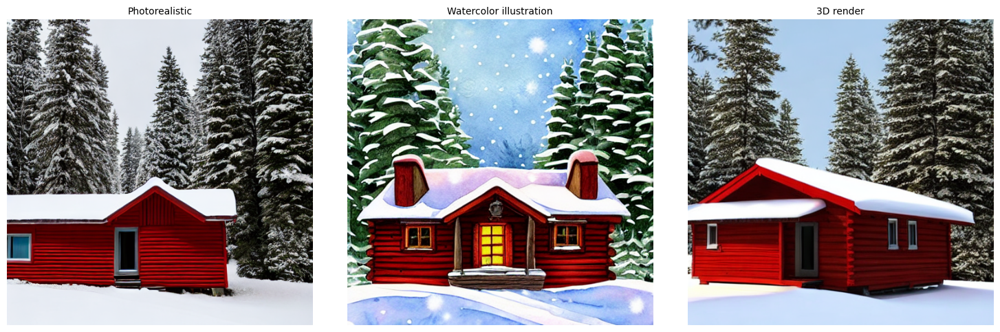

In [ ]:
prompt_variations = {
    "Photorealistic": (
        "professional landscape photograph of a small red wooden cabin in a snowy pine forest, "
        "warm light glowing from the windows, crisp winter morning, natural colors, sharp focus"
    ),
    "Watercolor illustration": (
        "watercolor storybook illustration of a small red wooden cabin in a snowy pine forest, "
        "warm glowing windows, delicate brush strokes, soft pastel colors, peaceful winter mood"
    ),
    "3D render": (
        "high quality 3D render of a small red wooden cabin in a snowy pine forest, "
        "warm glowing windows, volumetric winter sunlight, detailed materials, cinematic composition"
    ),
}

prompt_images, prompt_titles = [], []
for label, prompt_text in prompt_variations.items():
    image, elapsed = generate_image(
        prompt_text, negative_prompt=NEGATIVE_PROMPT,
        steps=25, guidance=7.5, seed=SEED
    )
    prompt_images.append(image)
    prompt_titles.append(label)
    record_result("Prompt variation", label, prompt_text, 25, 7.5, SEED, elapsed)
    save_image(image, f"02_prompt_{slugify(label)}.png")
    print(f"{label}: {elapsed:.2f} seconds")

show_image_grid(prompt_images, prompt_titles, columns=3, save_name="02_prompt_comparison.png")

### Prompt engineering: what to report

A useful prompt generally identifies **subject + setting + style + lighting/composition + detail**. A negative prompt lists elements you want to reduce, such as blur, watermarks or unwanted text. Negative prompts guide generation; they do not guarantee that every unwanted element will disappear.

After viewing the grid, note which wording changed the style most clearly and whether the negative prompt reduced visible artifacts. Base your statement on the displayed images.

## 8. Experiment B — Effect of inference steps

An inference step is one denoising update. This experiment uses one prompt, a fixed seed, guidance scale of 7.5 and one scheduler. Only the number of steps changes.

**Values tested:** 5, 10, 20, 30 and 50 steps. More steps often allow additional refinement but take longer; image quality does not necessarily increase at every step.

  0%|          | 0/5 [00:00<?, ?it/s]

Steps=5: 0.95 seconds


  0%|          | 0/10 [00:00<?, ?it/s]

Steps=10: 1.60 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Steps=20: 2.97 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

Steps=30: 4.34 seconds


  0%|          | 0/50 [00:00<?, ?it/s]

Steps=50: 7.14 seconds


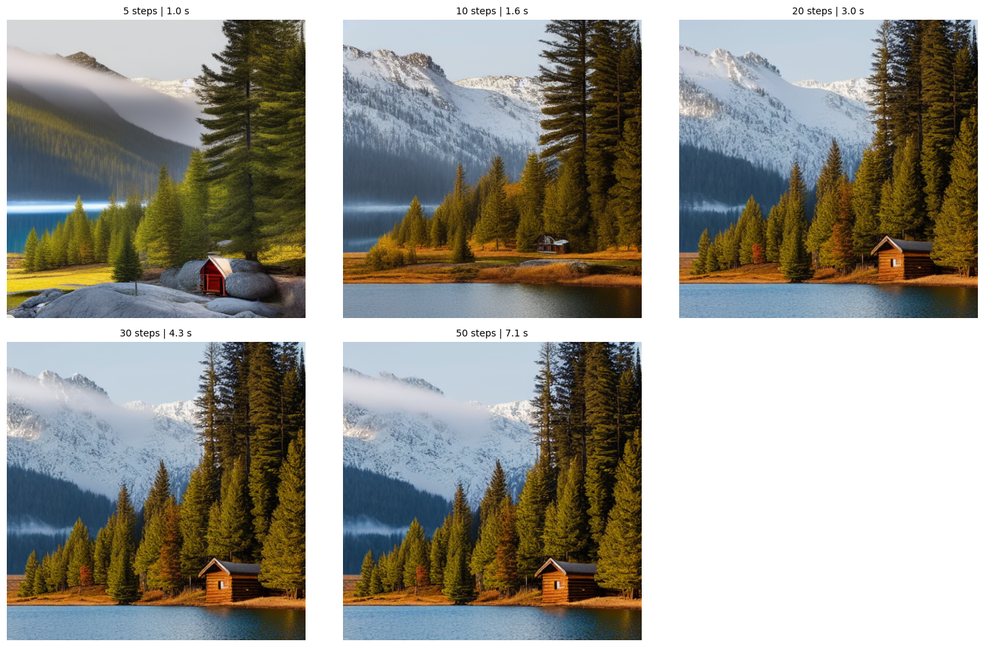

In [ ]:
analysis_prompt = (
    "a small wooden cabin beside a clear mountain lake, pine trees and distant snow-capped peaks, "
    "morning mist over the water, realistic landscape photography, natural light, detailed composition"
)

# Keep the scheduler fixed across the step experiment.
pipe.scheduler = DPMSolverMultistepScheduler.from_config(BASE_SCHEDULER_CONFIG)
step_values = [5, 10, 20, 30, 50]
step_images, step_titles = [], []

for n_steps in step_values:
    image, elapsed = generate_image(
        analysis_prompt, steps=n_steps, guidance=7.5, seed=SEED
    )
    step_images.append(image)
    step_titles.append(f"{n_steps} steps | {elapsed:.1f} s")
    record_result(
        "Inference steps", str(n_steps), analysis_prompt,
        n_steps, 7.5, SEED, elapsed, scheduler=type(pipe.scheduler).__name__
    )
    save_image(image, f"03_steps_{n_steps}.png")
    print(f"Steps={n_steps}: {elapsed:.2f} seconds")

show_image_grid(step_images, step_titles, columns=3, save_name="03_inference_steps_comparison.png")

### Inference-step interpretation

Compare the images for refinement, fine detail, edge clarity and artifacts. Use the recorded generation time to discuss the speed/quality trade-off. Avoid claiming that 50 steps must be best: the result depends on the prompt, model and scheduler, and improvements can become small after a certain number of steps.

## 9. Experiment C — Effect of guidance scale

Guidance scale controls how strongly the denoising process is steered toward the prompt. Low guidance can give the model more freedom, while very high guidance can sometimes cause harsh colors, artifacts or lower visual quality. The best value is prompt-dependent.

**Values tested:** 1, 3, 7.5, 12 and 18. The prompt, seed, steps and scheduler remain fixed.

  0%|          | 0/30 [00:00<?, ?it/s]

Guidance=1: 3.16 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

Guidance=3: 4.48 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

Guidance=7.5: 4.48 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

Guidance=12: 4.49 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

Guidance=18: 4.53 seconds


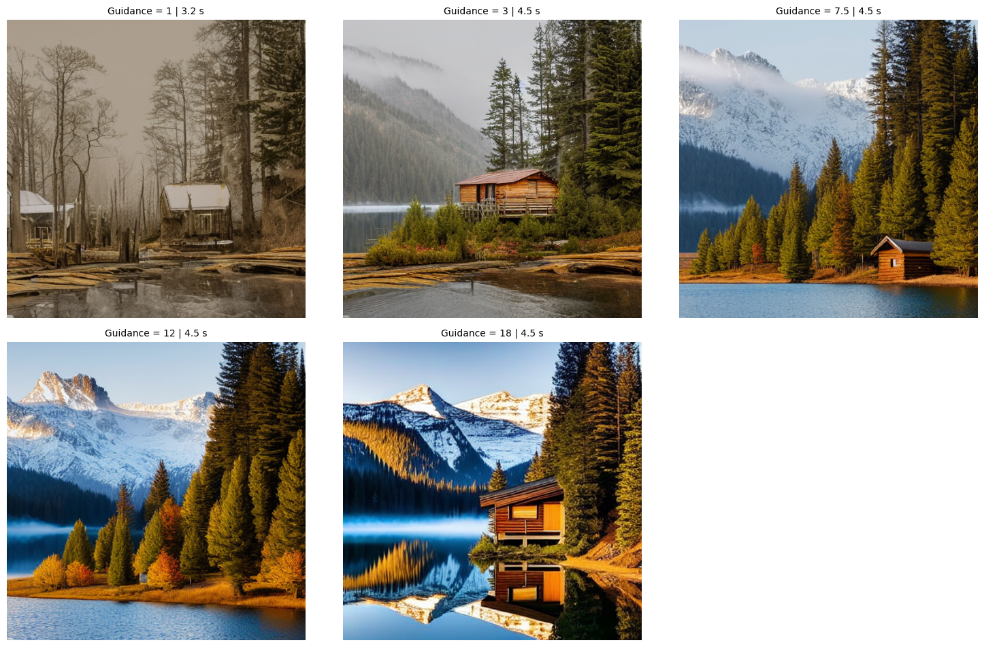

In [ ]:
# Continue to use the same DPM-Solver scheduler as the inference-step experiment.
guidance_values = [1.0, 3.0, 7.5, 12.0, 18.0]
guidance_images, guidance_titles = [], []

for scale in guidance_values:
    image, elapsed = generate_image(
        analysis_prompt, steps=30, guidance=scale, seed=SEED
    )
    guidance_images.append(image)
    guidance_titles.append(f"Guidance = {scale:g} | {elapsed:.1f} s")
    record_result(
        "Guidance scale", str(scale), analysis_prompt,
        30, scale, SEED, elapsed, scheduler=type(pipe.scheduler).__name__
    )
    save_image(image, f"04_guidance_{slugify(str(scale))}.png")
    print(f"Guidance={scale:g}: {elapsed:.2f} seconds")

show_image_grid(guidance_images, guidance_titles, columns=3, save_name="04_guidance_comparison.png")

### Guidance-scale interpretation

Check if the main prompt elements (cabin, lake, trees and mountain background) remain visible at each value. Judge both prompt adherence and visual quality. A strong guidance value is not automatically a high-quality value. At guidance scale 1, classifier-free text guidance is effectively disabled in this Diffusers pipeline, so the negative prompt is not expected to guide the result in the usual way.

## 10. Experiment D — Compare sampling schedulers

A scheduler controls how predicted noise is used to update the latent representation at each denoising step. This experiment compares five schedulers using the same prompt, seed, step count and guidance scale.

| Scheduler | General idea |
|---|---|
| **PNDM** | Uses pseudo-numerical updates across denoising steps. |
| **DDIM** | Uses a non-Markovian sampling formulation; with default settings it is often comparatively deterministic. |
| **Euler** | Uses an Euler numerical update for the denoising trajectory. |
| **Euler Ancestral** | Adds stochasticity through ancestral sampling. |
| **DPM-Solver Multistep** | Uses a multistep numerical solver designed for efficient diffusion sampling. |

Schedulers are not expected to produce pixel-identical images. Their numerical update rules differ; Euler Ancestral also uses stochastic sampling. The run time can vary because of GPU load, initialization and implementation details.

  0%|          | 0/30 [00:00<?, ?it/s]

PNDM: 4.87 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

DDIM: 4.65 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

Euler: 4.60 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

Euler Ancestral: 4.62 seconds


  0%|          | 0/30 [00:00<?, ?it/s]

DPM-Solver Multistep: 4.64 seconds


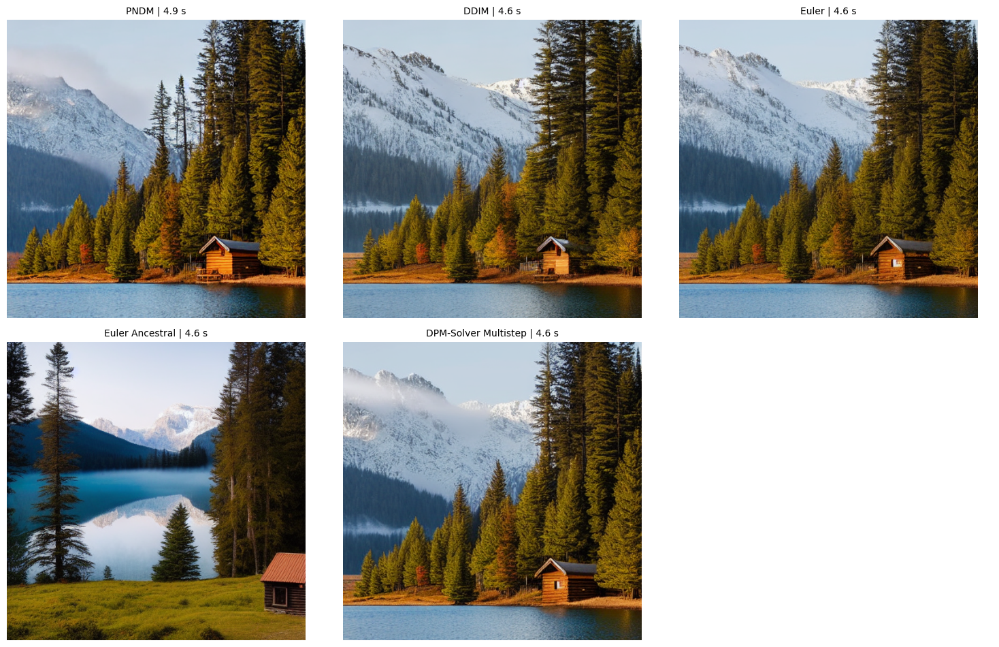

In [ ]:
scheduler_classes = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM-Solver Multistep": DPMSolverMultistepScheduler,
}

scheduler_images, scheduler_titles = [], []
for label, scheduler_class in scheduler_classes.items():
    # Rebuild each scheduler from the same original scheduler configuration.
    pipe.scheduler = scheduler_class.from_config(BASE_SCHEDULER_CONFIG)
    image, elapsed = generate_image(
        analysis_prompt, steps=30, guidance=7.5, seed=SEED
    )
    scheduler_images.append(image)
    scheduler_titles.append(f"{label} | {elapsed:.1f} s")
    record_result(
        "Scheduler comparison", label, analysis_prompt,
        30, 7.5, SEED, elapsed, scheduler=type(pipe.scheduler).__name__
    )
    save_image(image, f"05_scheduler_{slugify(label)}.png")
    print(f"{label}: {elapsed:.2f} seconds")

show_image_grid(scheduler_images, scheduler_titles, columns=3, save_name="05_scheduler_comparison.png")

### Scheduler interpretation

Compare composition, detail, texture, prompt adherence and artifacts. Report the scheduler that looked best **in your generated outputs**, not a universal winner. Check generation times, but remember that timing differences can be small and affected by hardware load. All tests use the same nominal seed and settings; different scheduler algorithms can still follow different denoising trajectories.

## 11. Collect results and compare generation time

The following table contains the actual elapsed times measured during your run. It does **not** invent a numerical image-quality score. After viewing each grid, add your own visual quality and prompt-adherence ratings on a 1–5 scale and write a short note describing the output. Suggested rubric: 1 = poor, 3 = acceptable, 5 = very good.

In [ ]:
results_df = pd.DataFrame(experiment_results)
results_df["visual_quality_1_to_5"] = ""  # Fill after inspecting the generated images.
results_df["prompt_adherence_1_to_5"] = "" # Fill after inspecting the generated images.
results_df["visual_observation"] = ""     # E.g. detail improved, colors harsh, artifact visible.

display(results_df)

csv_path = OUTPUT_DIR / "experiment_results.csv"
results_df.to_csv(csv_path, index=False)
print(f"Raw experiment log saved to: {csv_path}")

,experiment,variant,prompt,steps,guidance_scale,scheduler,seed,generation_seconds,visual_quality_1_to_5,prompt_adherence_1_to_5,visual_observation
0,Baseline generation,Astronaut greenhouse,a tiny astronaut tending glowing plants inside...,30,7.5,PNDMScheduler,42,7.032,,,
1,Prompt variation,Photorealistic,professional landscape photograph of a small r...,25,7.5,PNDMScheduler,42,3.806,,,
2,Prompt variation,Watercolor illustration,watercolor storybook illustration of a small r...,25,7.5,PNDMScheduler,42,3.789,,,
3,Prompt variation,3D render,high quality 3D render of a small red wooden c...,25,7.5,PNDMScheduler,42,3.819,,,
4,Inference steps,5,a small wooden cabin beside a clear mountain l...,5,7.5,DPMSolverMultistepScheduler,42,0.951,,,
5,Inference steps,10,a small wooden cabin beside a clear mountain l...,10,7.5,DPMSolverMultistepScheduler,42,1.597,,,
6,Inference steps,20,a small wooden cabin beside a clear mountain l...,20,7.5,DPMSolverMultistepScheduler,42,2.967,,,
7,Inference steps,30,a small wooden cabin beside a clear mountain l...,30,7.5,DPMSolverMultistepScheduler,42,4.336,,,
8,Inference steps,50,a small wooden cabin beside a clear mountain l...,50,7.5,DPMSolverMultistepScheduler,42,7.140,,,
9,Guidance scale,1.0,a small wooden cabin beside a clear mountain l...,30,1.0,DPMSolverMultistepScheduler,42,3.162,,,


Raw experiment log saved to: stable_diffusion_lab_outputs/experiment_results.csv


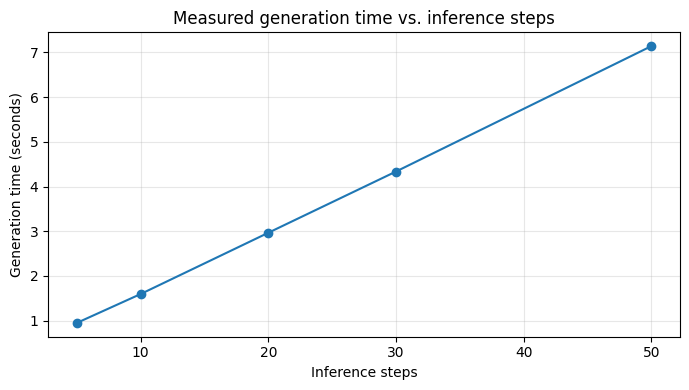

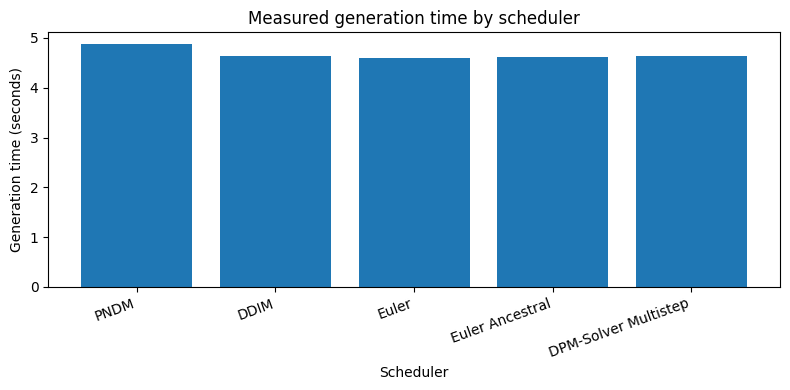

In [ ]:
# Plot measured generation time against inference steps.
step_df = results_df[results_df["experiment"] == "Inference steps"].copy()
if not step_df.empty:
    step_df["steps"] = pd.to_numeric(step_df["steps"])
    step_df = step_df.sort_values("steps")
    plt.figure(figsize=(7, 4))
    plt.plot(step_df["steps"], step_df["generation_seconds"], marker="o")
    plt.xlabel("Inference steps")
    plt.ylabel("Generation time (seconds)")
    plt.title("Measured generation time vs. inference steps")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "06_time_vs_steps.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Run the inference-step experiment first.")

# Plot the measured scheduler times (not image quality).
scheduler_df = results_df[results_df["experiment"] == "Scheduler comparison"].copy()
if not scheduler_df.empty:
    plt.figure(figsize=(8, 4))
    plt.bar(scheduler_df["variant"], scheduler_df["generation_seconds"])
    plt.xlabel("Scheduler")
    plt.ylabel("Generation time (seconds)")
    plt.title("Measured generation time by scheduler")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "07_scheduler_time.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Run the scheduler experiment first.")

## 12. Results and discussion

The experiments investigate how prompt wording and sampling settings influence Stable Diffusion outputs. The generated image grids, measured inference times and the manually completed ratings in the results table should be considered together.

### Discussion

1. **Prompt engineering:** The three prompts describe the same cabin scene using photographic, watercolor and 3D-rendering language. This controlled comparison illustrates how style-related words can influence the appearance of an image. The negative prompt asks the model to reduce blur, low quality, unwanted text and other artifacts, but it cannot guarantee their complete removal.

2. **Inference steps:** The experiment compares 5, 10, 20, 30 and 50 denoising steps while holding the prompt, seed, guidance scale and scheduler constant. Increasing the step count generally requires more computation and usually increases generation time. Additional steps may refine details, but improvements can diminish and are not guaranteed to make every image visually better.

3. **Guidance scale:** The experiment compares guidance values of 1, 3, 7.5, 12 and 18. A low value gives weaker text conditioning, while a higher value encourages closer adherence to the prompt. Very high guidance can sometimes produce harsh colors, exaggerated contrast or artifacts. The preferred setting is the one that gives a useful balance between prompt adherence and visual quality in the generated grid.

4. **Sampling schedulers:** PNDM, DDIM, Euler, Euler Ancestral and DPM-Solver Multistep use different numerical update methods. Even with the same nominal seed and prompt, they can produce visibly different results. Euler Ancestral also introduces stochasticity. Runtime alone does not determine the best scheduler; composition, detail, texture, artifacts and prompt adherence should also be considered.

5. **Limitations:** This is a small experiment using one pretrained model and a limited set of prompts and settings. Timing can vary with hardware load, precision and software versions, while visual ratings are subjective. Therefore, the results support comparisons within this run rather than a universal claim that one setting is always best.

### Observation summary

Use the generated images and the measured values in `experiment_results.csv` when describing the outcome. The most useful result is the setting that provides the best observed balance of visual quality, prompt adherence and generation time—not necessarily the largest step count or guidance scale. No numerical quality scores or winning configuration are assumed in advance; those should come from inspection of the outputs produced by this notebook.


## 13. Conclusion

In this practical, a pretrained Stable Diffusion text-to-image pipeline was set up using Hugging Face Diffusers. Text prompts were used to generate images, and controlled experiments were designed to examine prompt style, negative prompting, inference steps, guidance scale and five sampling schedulers. The notebook records generation time for each run and provides comparison grids and plots to support visual analysis.

The experiments demonstrate that image generation is affected by both the wording of the prompt and the sampling configuration. More inference steps can increase computation time without guaranteeing a proportional improvement in image quality. Guidance scale influences how strongly the output follows the prompt, while different schedulers can produce different image characteristics and runtimes. The preferred configuration should therefore be selected by considering the generated images, prompt adherence and measured time together.

The results are specific to the selected model, prompts, seed, software environment and hardware. The saved images and result table provide the evidence for comparing the tested configurations; visual quality ratings should be based on the actual outputs rather than assumed values.


## References

1. Hugging Face model card: [Stable Diffusion v1.5](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)
2. Hugging Face Diffusers documentation: [Stable Diffusion pipeline overview](https://huggingface.co/docs/diffusers/api/pipelines/stable_diffusion/overview)

**Submission checklist:** Run all cells in order; inspect the generated images; complete the observation table and conclusion with actual results; save the notebook with outputs; include the `stable_diffusion_lab_outputs` folder or its zipped contents if your instructor requests the generated images and result CSV.